# CA1 – Predicting Student Dropout and Academic Success
**Module:** Machine Learning  
**Student:** Yanjinkhorloo Munkhbold 
**Dataset:** Predict Students' Dropout and Academic Success (UCI Machine Learning Repository)  

## 1. Importing Libraries

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns

In [2]:
import matplotlib.pyplot as plt
import numpy as np

In [3]:
import warnings
warnings.filterwarnings('ignore')

## 2. Loading the Dataset

In [4]:
df=pd.read_csv('data/data.csv', sep=';')
df.rename(columns=({'Daytime/evening attendance\t': 'Daytime/evening attendance'}), inplace=True)
df.head

<bound method NDFrame.head of       Marital status  Application mode  Application order  Course  \
0                  1                17                  5     171   
1                  1                15                  1    9254   
2                  1                 1                  5    9070   
3                  1                17                  2    9773   
4                  2                39                  1    8014   
...              ...               ...                ...     ...   
4419               1                 1                  6    9773   
4420               1                 1                  2    9773   
4421               1                 1                  1    9500   
4422               1                 1                  1    9147   
4423               1                10                  1    9773   

      Daytime/evening attendance  Previous qualification  \
0                              1                       1   
1                    

In [5]:
print('Rows and columns:', df.shape)

Rows and columns: (4424, 37)


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4424 entries, 0 to 4423
Data columns (total 37 columns):
 #   Column                                          Non-Null Count  Dtype  
---  ------                                          --------------  -----  
 0   Marital status                                  4424 non-null   int64  
 1   Application mode                                4424 non-null   int64  
 2   Application order                               4424 non-null   int64  
 3   Course                                          4424 non-null   int64  
 4   Daytime/evening attendance                      4424 non-null   int64  
 5   Previous qualification                          4424 non-null   int64  
 6   Previous qualification (grade)                  4424 non-null   float64
 7   Nacionality                                     4424 non-null   int64  
 8   Mother's qualification                          4424 non-null   int64  
 9   Father's qualification                          4424

In [7]:
print('Total missing values:', df.isnull().sum().sum())
print('Duplicated rows:', df.duplicated().sum())

Total missing values: 0
Duplicated rows: 0


In [8]:
df.describe()

,Marital status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,...,Curricular units 1st sem (without evaluations),Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP
count,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,...,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000
mean,1.178571,18.669078,1.727848,8856.642631,0.890823,4.577758,132.613314,1.873192,19.561935,22.275316,...,0.137658,0.541817,6.232143,8.063291,4.435805,10.230206,0.150316,11.566139,1.228029,0.001969
std,0.605747,17.484682,1.313793,2063.566416,0.311897,10.216592,13.188332,6.914514,15.603186,15.343108,...,0.690880,1.918546,2.195951,3.947951,3.014764,5.210808,0.753774,2.663850,1.382711,2.269935
min,1.000000,1.000000,0.000000,33.000000,0.000000,1.000000,95.000000,1.000000,1.000000,1.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,7.600000,-0.800000,-4.060000
25%,1.000000,1.000000,1.000000,9085.000000,1.000000,1.000000,125.000000,1.000000,2.000000,3.000000,...,0.000000,0.000000,5.000000,6.000000,2.000000,10.750000,0.000000,9.400000,0.300000,-1.700000
50%,1.000000,17.000000,1.000000,9238.000000,1.000000,1.000000,133.100000,1.000000,19.000000,19.000000,...,0.000000,0.000000,6.000000,8.000000,5.000000,12.200000,0.000000,11.100000,1.400000,0.320000
75%,1.000000,39.000000,2.000000,9556.000000,1.000000,1.000000,140.000000,1.000000,37.000000,37.000000,...,0.000000,0.000000,7.000000,10.000000,6.000000,13.333333,0.000000,13.900000,2.600000,1.790000
max,6.000000,57.000000,9.000000,9991.000000,1.000000,43.000000,190.000000,109.000000,44.000000,44.000000,...,12.000000,19.000000,23.000000,33.000000,20.000000,18.571429,12.000000,16.200000,3.700000,3.510000


In [9]:
print(df['Target'].value_counts())
print(df['Target'].value_counts()/len(df)*100)

Target
Graduate    2209
Dropout     1421
Enrolled     794
Name: count, dtype: int64
Target
Graduate    49.932188
Dropout     32.120253
Enrolled    17.947559
Name: count, dtype: float64


**Observations:**
- The dataset has 4424 rows and 37 columns.
- Missing values:0; duplicated rows:0.
- The target has 3 classes: Graduate (49.9%), Dropout (32.1%), Enrolled (17.9%), so the classes are imbalanced. Because Enrolled is the smallest class, the models may struggle to predict it, so F1-score will be checked alongside accuracy and stratify will be used when splitting.

## 3. Exploraty Data Analysis (EDA)

In [10]:
target_mapping={'Dropout': 0, 'Enrolled': 1, 'Graduate': 2}
df['Target']=df['Target'].map(target_mapping)
print(df['Target'].value_counts())

Target
2    2209
0    1421
1     794
Name: count, dtype: int64


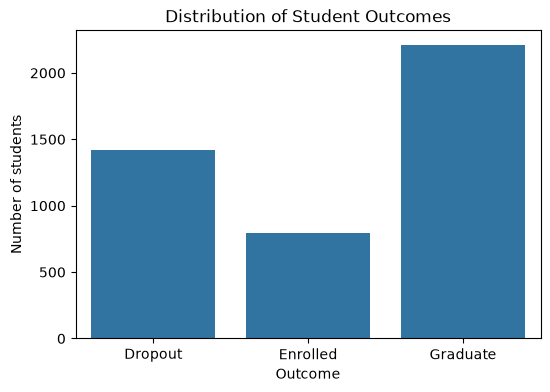

In [11]:
plt.figure(figsize = (6, 4))
sns.countplot(x = 'Target', data = df)
plt.title('Distribution of Student Outcomes')
plt.xticks([0, 1, 2], ['Dropout', 'Enrolled', 'Graduate'])
plt.xlabel('Outcome')
plt.ylabel('Number of students')
plt.show()

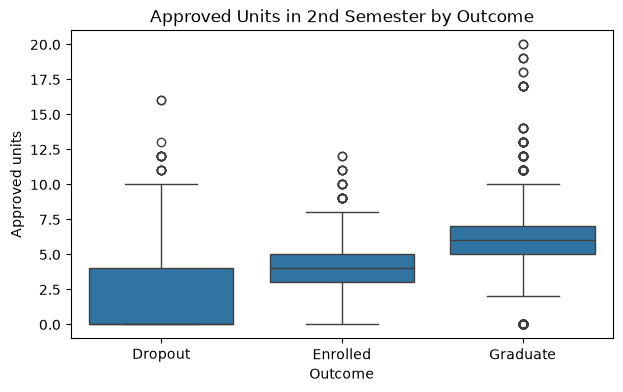

In [12]:
plt.figure(figsize=(7, 4))
sns.boxplot(data=df, x='Target', y='Curricular units 2nd sem (approved)')
plt.title('Approved Units in 2nd Semester by Outcome')
plt.xticks([0, 1, 2], ['Dropout', 'Enrolled', 'Graduate'])
plt.xlabel('Outcome')
plt.ylabel('Approved units')
plt.show()

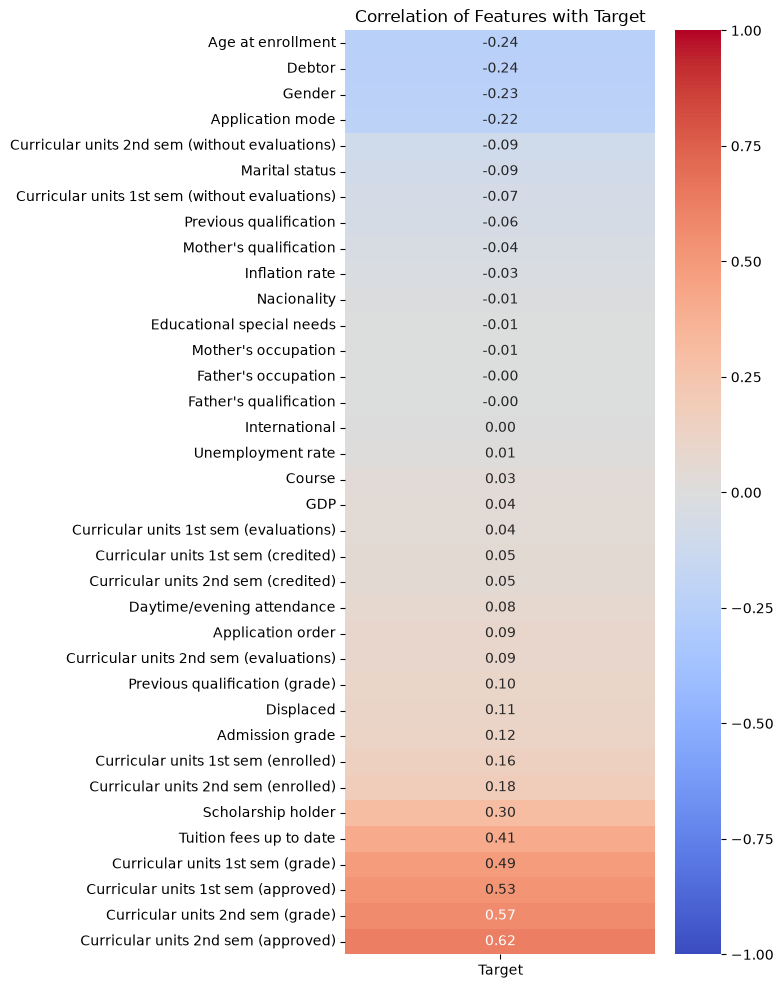

In [16]:
# Correlation of each feature with the Target, sorted from lowest to highest
corr_target=df.corr()[['Target']].sort_values(by='Target')
corr_target=df.corr()[['Target']].drop('Target').sort_values(by='Target')
plt.figure(figsize=(5, 12))
sns.heatmap(corr_target, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlation of Features with Target')
plt.show()

**EDA Observations:**
- Boxplot: Students who dropped out had fewer approved subjects in the 2nd semester compared to students who graduated.
- Academic performance: The number of approved subjects (r=0.62) and grades (r=0.57) in the 2nd semester have the strongest relationship with graduation. This means students who perform better academically are more likely to graduate.
- Financial factors: Students who pay their tuition fees on time (r=0.41) and receive scholarships (r=0.30) are more likely to garduate. Students with unoaid debts (r=-0.24) are more likely to drop out.
- Other factors: Nationality, parents, occupations, unemployment rate, and GDP have very little relationship with the final outcome
- Next step: Some categorical features, such as Course and Application mode, can not be properly understood using correlation. Therefore, we will use a Decision Tree to check their importance.

## 4. Data Pre-processing

In [17]:
X=df.drop(['Target'], axis=1).values
y=df['Target'].values
feature_names=df.drop(['Target'], axis=1).columns
X.shape, y.shape

((4424, 36), (4424,))

In [19]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
X_train, X_test, y_train, y_test=train_test_split(X, y, test_size=0.25, random_state=42)
scaler=StandardScaler()
X_train_scaled=scaler.fit_transform(X_train)
X_test_scaled=scaler.transform(X_test)
print('Training rows:', X_train.shape[0])
print('Test rows:', X_test.shape[0])

Training rows: 3318
Test rows: 1106


**Pre-processing notes:**
- X contains 36 input features and y contains the target (0=Droout, 1=Enrolled, 2=Graduate).
- All features are already numeric and there are no missing values, so no encoding or imputation is needed.
- kNN and SVM use distances between points, so features with large values (e.g. Admission grade) would dominate small ones (e.g. Debtor 0/1). Therefore StandardScaler is applied. It is fitted on the training set only, to avoid data leakage.

## 5. Model Training with Three Splits and Cross-Validation
Three models are compared: Decision Tree, k-Nearest Neighbours and Support Vector Machine.
Each model is trained with three test sizes (5%, 15%, 25%), and 10-fold cross-validation is used on the training set.

In [21]:
from sklearn.model_selection import cross_val_score
from sklearn.tree import DecisionTreeClassifier 
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
test_sizes=[0.05, 0.15, 0.25]

In [23]:
dt_train_acc = np.zeros(3)
dt_test_acc = np.zeros(3)
dt_cv_acc = np.zeros(3)

for i, size in enumerate(test_sizes):
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = size, random_state = 42)
    X_train = scaler.fit_transform(X_train)
    X_test = scaler.transform(X_test)

    dt = DecisionTreeClassifier(random_state = 42)
    dt.fit(X_train, y_train)
    dt_train_acc[i] = dt.score(X_train, y_train)
    dt_test_acc[i] = dt.score(X_test, y_test)
    dt_cv_acc[i] = cross_val_score(dt, X_train, y_train, cv = 10).mean()

print('Train:', dt_train_acc)
print('Test:', dt_test_acc)
print('CV:', dt_cv_acc)

Train: [1. 1. 1.]
Test: [0.70720721 0.67018072 0.6835443 ]
CV: [0.68777457 0.67978723 0.69529629]


In [24]:
knn_train_acc = np.zeros(3)
knn_test_acc = np.zeros(3)
knn_cv_acc = np.zeros(3)

for i, size in enumerate(test_sizes):
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = size, random_state = 42)
    X_train = scaler.fit_transform(X_train)
    X_test = scaler.transform(X_test)

    knn = KNeighborsClassifier(n_neighbors = 5)
    knn.fit(X_train, y_train)
    knn_train_acc[i] = knn.score(X_train, y_train)
    knn_test_acc[i] = knn.score(X_test, y_test)
    knn_cv_acc[i] = cross_val_score(knn, X_train, y_train, cv = 10).mean()

print('Train:', knn_train_acc)
print('Test:', knn_test_acc)
print('CV:', knn_cv_acc)

Train: [0.79271775 0.79228723 0.79505726]
Test: [0.75225225 0.70933735 0.69801085]
CV: [0.69323832 0.69361702 0.69199214]


In [25]:
svm_train_acc = np.zeros(3)
svm_test_acc = np.zeros(3)
svm_cv_acc = np.zeros(3)

for i, size in enumerate(test_sizes):
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = size, random_state = 42)
    X_train = scaler.fit_transform(X_train)
    X_test = scaler.transform(X_test)

    svm = SVC()
    svm.fit(X_train, y_train)
    svm_train_acc[i] = svm.score(X_train, y_train)
    svm_test_acc[i] = svm.score(X_test, y_test)
    svm_cv_acc[i] = cross_val_score(svm, X_train, y_train, cv = 10).mean()

print('Train:', svm_train_acc)
print('Test:', svm_test_acc)
print('CV:', svm_cv_acc)

Train: [0.8210376  0.82340426 0.82700422]
Test: [0.77027027 0.76355422 0.7522604 ]
CV: [0.75940561 0.75797872 0.7606996 ]


In [26]:
df_results = pd.DataFrame({
    'Test size': ['5%', '15%', '25%'],
    'DT test': dt_test_acc, 'DT CV': dt_cv_acc,
    'kNN test': knn_test_acc, 'kNN CV': knn_cv_acc,
    'SVM test': svm_test_acc, 'SVM CV': svm_cv_acc
})
df_results

,Test size,DT test,DT CV,kNN test,kNN CV,SVM test,SVM CV
0,5%,0.707207,0.687775,0.752252,0.693238,0.770270,0.759406
1,15%,0.670181,0.679787,0.709337,0.693617,0.763554,0.757979
2,25%,0.683544,0.695296,0.698011,0.691992,0.752260,0.760700


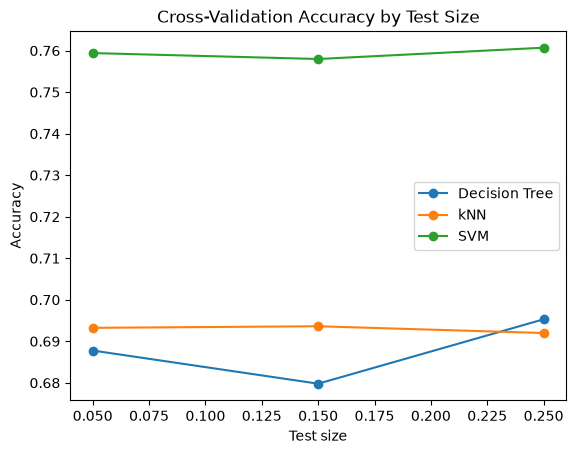

In [27]:
plt.plot(test_sizes, dt_cv_acc, marker = 'o', label = 'Decision Tree')
plt.plot(test_sizes, knn_cv_acc, marker = 'o', label = 'kNN')
plt.plot(test_sizes, svm_cv_acc, marker = 'o', label = 'SVM')
plt.title('Cross-Validation Accuracy by Test Size')
plt.xlabel('Test size')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

**Model Comparison Observations:**
- SVM performed best on every split, with CV accuracy of about 0.76 and test accuracy between 0.75 and 0.77. kNN came second (CV about 0.69) and Decision Tree was lowest (CV 0.68–0.70).
- Decision Tree shows clear overfitting: its training accuracy is 1.00 (100%) on all splits, but test and CV accuracy are only about 0.68–0.70. The tree has memorised the training data and does not generalise well. This will be addressed by tuning max_depth.
- kNN has a smaller gap (train about 0.79 vs CV about 0.69), so it overfits slightly.
- SVM has the smallest gap (train about 0.82 vs CV about 0.76), so it generalises best.
- Test accuracy for kNN dropped from 0.75 (5%) to 0.70 (25%), while its CV accuracy stayed at 0.69. With only 222 test rows in the 5% split, the test score depends on which students are in the test set, so it is less reliable. Cross-validation gives a more stable estimate.
- CV accuracy for all three models was almost the same across the three splits, so the amount of training data (75%–95%) did not change performance much.

## 6. Hyperparameter Tuning (GridSearchCV)
GridSearchCV tries every combination of the given hyperparameters using cross-validation on the training set, and selects the best one. Tuning is done on the 25% test split.

In [28]:
from sklearn.model_selection import GridSearchCV
X_train, X_test, y_train, y_test=train_test_split(X, y, test_size=0.25, random_state=42)
X_train=scaler.fit_transform(X_train)
X_test=scaler.transform(X_test)

In [29]:
param_grid_dt={'max_depth': [2, 3, 4, 5, 6, 8, 10]}

grid_dt=GridSearchCV(DecisionTreeClassifier(random_state=42), param_grid_dt)
grid_dt.fit(X_train, y_train)
print('Best Parameters:', grid_dt.best_params_)
print('Test accuracy:', grid_dt.score(X_test, y_test))

Best Parameters: {'max_depth': 6}
Test accuracy: 0.7269439421338155


In [30]:
param_grid_knn = {'n_neighbors': [3, 5, 7, 9, 11, 15, 21]}

grid_knn = GridSearchCV(KNeighborsClassifier(), param_grid_knn)
grid_knn.fit(X_train, y_train)

print('Best Parameters:', grid_knn.best_params_)
print('Test accuracy:', grid_knn.score(X_test, y_test))

Best Parameters: {'n_neighbors': 15}
Test accuracy: 0.7007233273056058


In [31]:
param_grid_svm = {
    'C': [0.1, 1, 10, 100],
    'gamma': [1, 0.1, 0.01, 0.001],
    'kernel': ['rbf']
}

grid_svm = GridSearchCV(SVC(), param_grid_svm)
grid_svm.fit(X_train, y_train)

print('Best Parameters:', grid_svm.best_params_)
print('Test accuracy:', grid_svm.score(X_test, y_test))

Best Parameters: {'C': 100, 'gamma': 0.001, 'kernel': 'rbf'}
Test accuracy: 0.7640144665461122


In [32]:
df_tuning = pd.DataFrame({
    'Model': ['Decision Tree', 'kNN', 'SVM'],
    'Default test accuracy': [dt_test_acc[2], knn_test_acc[2], svm_test_acc[2]],
    'Tuned test accuracy': [grid_dt.score(X_test, y_test), grid_knn.score(X_test, y_test), grid_svm.score(X_test, y_test)],
    'Best parameters': [grid_dt.best_params_, grid_knn.best_params_, grid_svm.best_params_]
})
df_tuning

,Model,Default test accuracy,Tuned test accuracy,Best parameters
0,Decision Tree,0.683544,0.726944,{'max_depth': 6}
1,kNN,0.698011,0.700723,{'n_neighbors': 15}
2,SVM,0.752260,0.764014,"{'C': 100, 'gamma': 0.001, 'kernel': 'rbf'}"


**Tuning Observations:**
- All three models improved after tuning on the 25% split.
- Decision Tree improved the most (0.684 → 0.727). Limiting the depth to 6 stopped the tree from memorising the training data, which reduced the overfitting seen in Section 5 (train accuracy 1.00).
- kNN improved only slightly (0.698 → 0.701). A larger k (15) averages over more neighbours, which makes predictions smoother and less sensitive to noise.
- SVM remained the best model (0.752 → 0.764). The best combination was a high C (100) with a small gamma (0.001), meaning a smoother decision boundary that still fits the training data closely.
- Note: C = 1000 from the tutorial grid was not used because it made training very slow on this dataset.

## 7. Evalution of the Best Model
The tuned SVM is evaluated in more detail with a confusion matrix and classification report, to see how well each class is predicted.

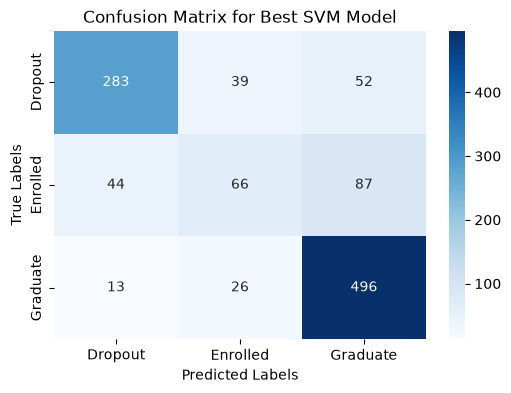

In [33]:
from sklearn.metrics import confusion_matrix, classification_report
svm_predictions=grid_svm.predict(X_test)
cm=confusion_matrix(y_test, svm_predictions)
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
           xticklabels=['Dropout', 'Enrolled', 'Graduate'],
           yticklabels=['Dropout', 'Enrolled', 'Graduate'])
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix for Best SVM Model')
plt.show()

In [36]:
print(classification_report(y_test, svm_predictions, target_names=['Dropout', 'Enrolled', 'Graduate']))

              precision    recall  f1-score   support

     Dropout       0.83      0.76      0.79       374
    Enrolled       0.50      0.34      0.40       197
    Graduate       0.78      0.93      0.85       535

    accuracy                           0.76      1106
   macro avg       0.71      0.67      0.68      1106
weighted avg       0.75      0.76      0.75      1106



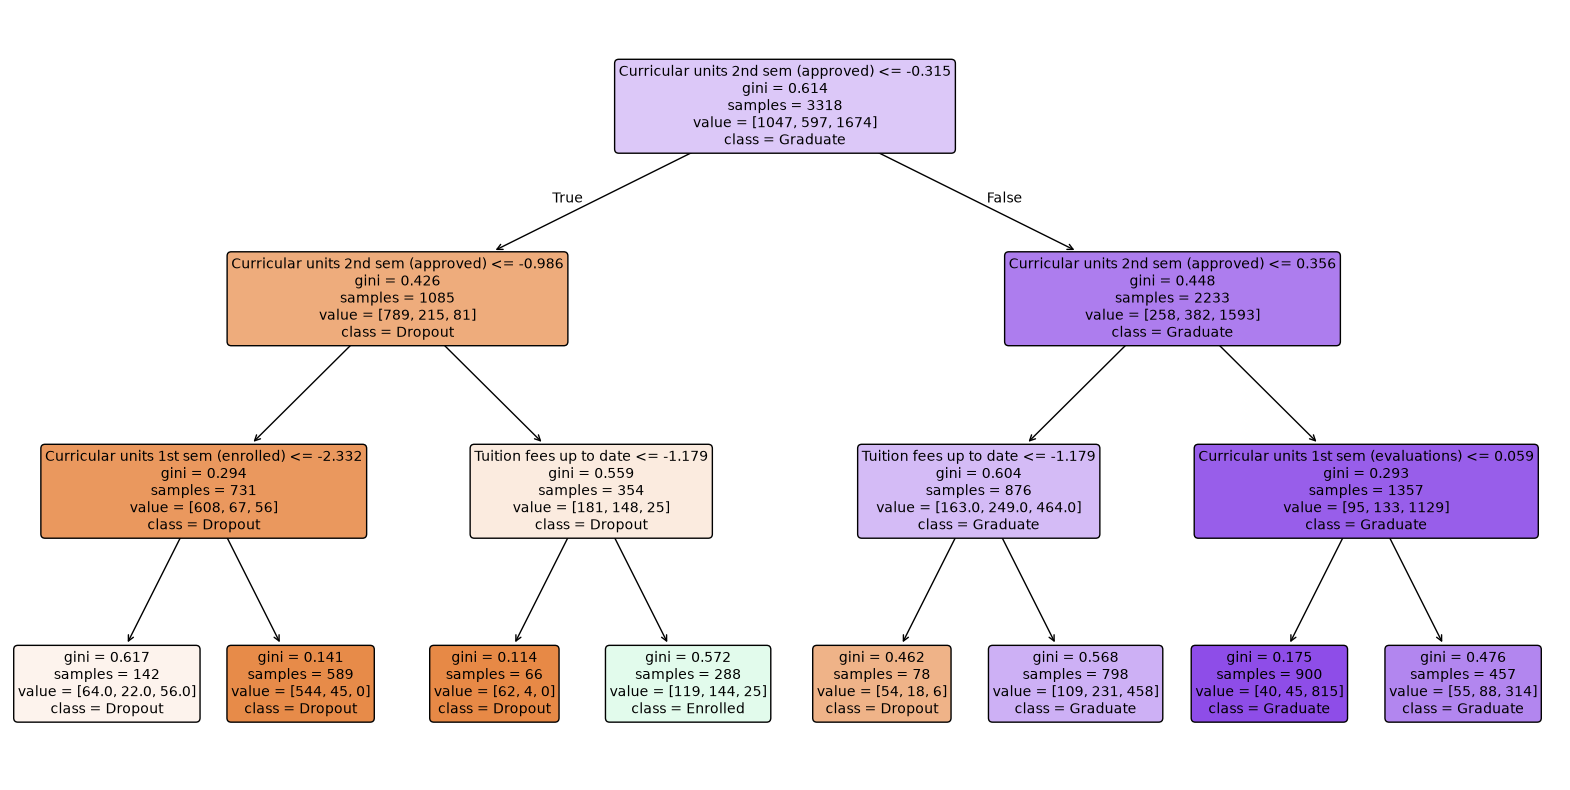

In [37]:
from sklearn.tree import plot_tree
dt_small=DecisionTreeClassifier(max_depth=3, random_state=42)
dt_small.fit(X_train, y_train)

plt.figure(figsize=(20, 10))
plot_tree(dt_small, filled=True, feature_names=feature_names.tolist(), class_names=['Dropout', 'Enrolled', 'Graduate'], rounded=True, fontsize=10)
plt.show()

**Evaluation Observations:**
- The tuned SVM reached 0.76 accuracy on the 25% test set (1106 students).
- Graduate was predicted best (recall 0.93, F1 0.85), and Dropout was predicted well (precision 0.83, recall 0.76, F1 0.79). This is the most important class for the problem, because the goal is to identify students at risk of dropping out.
- Enrolled was predicted poorly (recall 0.34, F1 0.40). Most Enrolled students were classified as Graduate (87) or Dropout (44). This is expected because Enrolled is the smallest class (17.9%) and these students are still in progress, so their profile overlaps with both other groups. The Decision Tree showed the same problem.
- The macro average F1 (0.68) is lower than the accuracy (0.76), which confirms that accuracy alone hides the weak performance on the minority class.

## 8. Overfitting and Underfitting
To show how model complexity affects generalisation, the Decision Tree is trained with depths from 1 to 20, and training and test accuracy are compared.

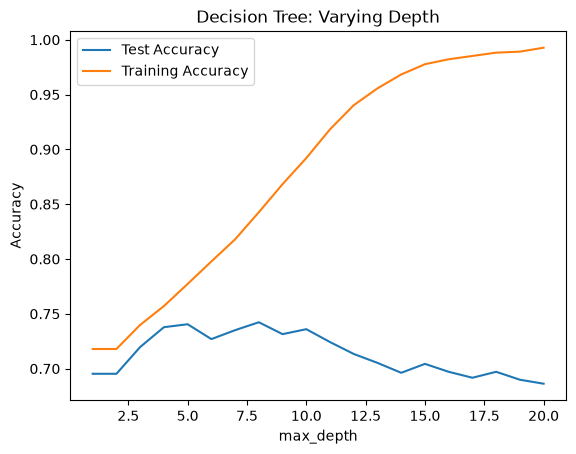

In [40]:
depths=np.arange(1, 21)
train_accuracy=np.zeros(len(depths))
test_accuracy=np.zeros(len(depths))
for i, d in enumerate(depths):
    dt=DecisionTreeClassifier(max_depth=d, random_state=42)
    dt.fit(X_train, y_train)
    train_accuracy[i]=dt.score(X_train, y_train)
    test_accuracy[i]=dt.score(X_test, y_test)

plt.title('Decision Tree: Varying Depth')
plt.plot(depths, test_accuracy, label='Test Accuracy')
plt.plot(depths, train_accuracy, label='Training Accuracy')
plt.legend()
plt.xlabel('max_depth')
plt.ylabel('Accuracy')
plt.show()

**Overfitting and Underfitting Observations**
- At depth 1-2 both training and test accuracy are low (about 0.72 and 0.70), so the tree is too simple and underfits.
- Test accuracy is highest (about 0.74) between depth 4 and 8.
- After depth 10, training accuracy keeps rising to almost 1.00 while test accuracy falls to about 0.69. The gap of abot 0.30 shows strong overfitting: the tree memories the training data instead of learning general patterns.
- GridSearcjCV chose depth 6, which is inside the best range. It was selected using cross-validation on the training set only, not the test set, so the test result remains an honest estimate of performance on new students.

## 9. Conclusion
- In this study, three machine learning models (Decision Tree, kNN, and SVM) were used to predict whether students would drop out, continue their studies, or graduate. The models were tested using three different test sizes (5%, 15%, and 25%) and 10-fold cross-validation.
- The results showed that SVM was the best-performing model. After using GridSearchCV to improve the models, SVM achieved 76.4% accuracy, Decision Tree achieved 72.7%, and kNN achieved 70.1%.
- The original Decision Tree model had an overfitting problem because it achieved 100% accuracy on the training data. By limiting the tree depth, overfitting was reduced and test accuracy improved by 4.3 percentage points.
- The results from the three different test sizes were very similar. This shows that the models produced stable results and were not affected by just one data split.
- Based on the correlation analysis and the Decision Tree, the most important factors in predicting student outcomes were academic performance in the second semester and whether students paid their tuition fees on time.
- The SVM model was able to identify students who might drop out with 76% recall. This is useful because universities can identify students at risk and provide support earlier. However, the model had difficulty identifying students who continued their studies, with only 34% recall. This may be because the Enrolled group had fewer students than the other groups and shared similar characteristics with them.
- For future work, techniques such as balancing the dataset could be used to improve the prediction of the smaller Enrolled group. Another option is to combine the Enrolled group with another class and compare the results.

Overall, this study showed that SVM was the most effective model for predicting student outcomes. These models could help universities identify students who are at risk of dropping out and provide support before it is too late. 